# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

ALPHA = 0.05  # уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

**Требования:**
- явно задайте разность $d_i$ (какой столбец из какого вычитается) и параметр $\mu_d$ (что он означает по-русски);
- запишите $H_0$ и $H_1$ формулами;
- обоснуйте выбор типа альтернативы (односторонняя или двусторонняя) в 1–2 предложениях;
- укажите правило принятия решения.

### Подсказки

- Данные парные, поэтому гипотезы формулируются **об одном параметре**: среднем значении разностей $\mu_d$, а не о двух средних.
- Определите разность как $d_i = \text{after}_i - \text{before}_i$. Подумайте, **какой знак** будет у $d_i$, если приложение помогает
  (время засыпания уменьшилось → разность положительная или отрицательная?). От этого зависит, в какую сторону направлена $H_1$.
- Направление альтернативы выбирается из логики задачи **до** просмотра результатов. Что именно хочет доказать компания?
- Для записи формул в Markdown используйте синтаксис `$\mu_d < 0$`.

### Ваш ответ

_(Дважды щёлкните по ячейке, чтобы отредактировать. Впишите гипотезы ниже.)_

**Определение разности:** Данные **парные**: каждая строка — один и тот же человек, измеренный дважды. Поэтому мы считаем разность для каждого сотрудника как: $d_i = \text{after\_min}_i - \text{before\_min}_i$.

**Параметр:** нас интересует **среднее  разностей времени засыпания** $\mu_d$
(на сколько в среднем меняется время засыпания).

**H₀:** $\mu_d$ = 0. Приложение не влияет на время засыпания.

**H₁:** $\mu_d$ < 0. Приложение сокращает время засыпания.

**Обоснование типа альтернативы:** Альтернатива односторонняя («меньше нуля»), так как бизнес-вопрос конкретно спрашивает, «сокращает ли» приложение время засыпания. Мы не проверяем гипотезу о том, что приложение *меняет* время (в любую сторону), а ищем доказательство именно улучшения (сокращения).


**Правило принятия решения:** Если $p\text{-value} < \alpha = 0.05$, отвергаем $H_0$ в пользу $H_1$  (приложение сокращает время засыпания). Иначе — **не находим достаточных доказательств**
в пользу $H_1$ (но это не означает, что $H_0$ доказана).

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
# размер, типы, пропуски
df.info()
df.isna().sum()

# дубликаты
print("Полные дубликаты строк:", df.duplicated().sum())
print("Повторы participant_id:", df["participant_id"].duplicated().sum())

# мин/макс (числовые столбцы)
df.describe()

# нечисловые значения в столбцах времени
for col in ["before_min", "after_min"]:
    coerced = pd.to_numeric(df[col], errors="coerce")
    bad = df.index[coerced.isna() & df[col].notna()]
    print(col, "-> текстовые значения в строках:", bad.tolist(), df.loc[bad, col].tolist())

# значения вне допустимых диапазонов
for col, lo, hi in [("before_min", 5, 180), ("after_min", 5, 180), ("age", 18, 80)]:
    num = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce")
    bad = df.index[num.notna() & ~num.between(lo, hi)]
    print(col, "-> вне диапазона:", df.loc[bad, col].tolist())



<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB
Полные дубликаты строк: 2
Повторы participant_id: 2
before_min -> текстовые значения в строках: [49] ['37,0']
after_min -> текстовые значения в строках: [34] ['18,0']
before_min -> вне диапазона: [999]
after_min -> вне диапазона: [400, -20]
age -> вне диапазона: [150.0, 0.0]


**Список обнаруженных проблем:**
1. **Размер таблицы, типы столбцов, число непустых значений в каждом столбце:**\
В исхдных данных 52 строки, а участников 50. Имеются дубли 2-х строк.\
Столбцы before_min и after_min имеют некорректные типы object.\
Количество не пустых значенй в столбцах age, before_min, after_min не равно 52. Имеются пропуски данных.
2. **Пропуски по столбцам:** в age 2 пропуска , before_min 1 пропуск, в after_min 2 пропуска.
3. **Дубликаты и повторы:** выявлено 2 полных дупликата строк и 2 повтора идентификатора участника participant_id
4. **Некоректные значения данных:** в столбцах age, before_min и after_min присутствуют данные вне допустимого диапазона.
5. **Не верный тип данных:** В столбцах before_min и after_min присутствуют данные значения которых не соответсвуют ожидаемому типу, так как в качестве десятичного разделителя вместо точки использована запятая.

### 2.2–2.3. Очистка и возрастные группы

In [4]:
# ВАШ КОД: аудит (info, пропуски, дубликаты, min/max, нечисловые значения)
print("\n2.1.1. Размер таблицы, типы столбцов, число непустых значений в каждом столбце: ")
print(df.info())

print("\n2.1.2. Число пропусков по столбцам:")
print(df.isna().sum())

print("\n2.1.3. Полные дубликаты и повторы participant_id:")
print(f"   Полных дубликатов строк: {df.duplicated().sum()}")
print(f"   Повторов participant_id: {df['participant_id'].duplicated().sum()}")

print("\n2.1.4. Минимальные и максимальные значения числовых столбцов:")
bad_range_value_len = 0
for column, low_value, high_value in [("before_min", 5, 180), ("after_min", 5, 180), ("age", 18, 80)]:
    numeric_column = pd.to_numeric(df[column], errors='coerce')
    bad_index = df.index[numeric_column.notna() & ~numeric_column.between(low_value, high_value)]
    print(column, " значения вне диапазона:", df.loc[bad_index, column].tolist())
    bad_range_value_len += len(bad_index)

print("\n2.1.5. Столбцы, в которых тип данных не соответствует ожидаемому:")
bad_rows_len = 0
for column in ['age', 'before_min', 'after_min']:
    numeric_column = pd.to_numeric(df[column], errors='coerce')
    bad_rows = df[(df[column].notna()) & (numeric_column.isna())]
    if len(bad_rows) > 0:
        bad_rows_len += len(bad_rows)
        print(f"\n   {column}: найдены нечисловые значения:")
        print(f"   Строки: {bad_rows.index.tolist()}")
        print(f"   Значения: {bad_rows[column].unique()}")



2.1.1. Размер таблицы, типы столбцов, число непустых значений в каждом столбце: 
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB
None

2.1.2. Число пропусков по столбцам:
participant_id    0
age               2
before_min        1
after_min         2
dtype: int64

2.1.3. Полные дубликаты и повторы participant_id:
   Полных дубликатов строк: 2
   Повторов participant_id: 2

2.1.4. Минимальные и максимальные значения числовых столбцов:
before_min  значения вне диапазона: [999]
after_min  значения вне диапазона: [400, -20]
age  значения вне диапазона: [150.0, 0.0]

2.1.5. Столбцы, в которых тип данных не соответствует о

In [5]:
# ВАШ КОД: создайте df_clean = df.copy() и примените правила 1-4 по порядку
# 2.2 Очистка
df_clean = df.copy()
journal_list = []

# 2.2.1 Замена запятой на точку
for column in ["before_min", "after_min"]:
    df_clean[column] = pd.to_numeric(
        df_clean[column].astype(str).str.replace(",", ".", regex=False),
        errors="coerce",
    )
after_len = len(df_clean)
journal_list.append({"action": "2.2.1 Замена запятой на точку", "changed_data": f"Изменено строк: {bad_rows_len}",
                     "data_len": f"Всего строк данных {after_len}"})
print(list(journal_list[-1].values()))
# 2.2.2 Удаляем дубликаты
before_len = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first")
after_len = len(df_clean)
changed_str = before_len - after_len
journal_list.append({"action": "2.2.2 Удаляем дубликаты", "changed_data": f"Удалено дублирующих строк: {changed_str}",
                     "data_len": f"Всего строк данных {after_len}"})
print(list(journal_list[-1].values()))
# 2.2.3 Замена значений вне диапазона на пропуски
df_clean.loc[~df_clean["before_min"].between(5, 180), "before_min"] = np.nan
df_clean.loc[~df_clean["after_min"].between(5, 180), "after_min"] = np.nan
df_clean.loc[~df_clean["age"].between(18, 80), "age"] = np.nan
after_len = len(df_clean)
journal_list.append({"action": "2.2.3 Замена значений вне диапазона на пропуски",
                     "changed_data": f"Всего изменено значений: {bad_range_value_len}",
                     "data_len": f"Всего строк данных {after_len}"})
print(list(journal_list[-1].values()))
# 2.2.4 Удаление неполных пар
before_len = len(df_clean)
df_clean = df_clean.dropna(subset=["before_min", "after_min"]).reset_index(drop=True)
after_len = len(df_clean)
changed_str = before_len - after_len
journal_list.append(
    {"action": "2.2.4 Удаление неполных пар", "changed_data": f"Удалено строк с неполными парами: {changed_str}",
     "data_len": f"Всего строк данных {after_len}"})
print(list(journal_list[-1].values()))
# 2.2.5 Проверка типов столбцов: before_min и after_min должны быть числовыми (float)
print("2.2.5 Проверка типов столбцов: before_min и after_min должны быть числовыми (float)")
print(df_clean[["before_min", "after_min"]].dtypes)

['2.2.1 Замена запятой на точку', 'Изменено строк: 2', 'Всего строк данных 52']
['2.2.2 Удаляем дубликаты', 'Удалено дублирующих строк: 2', 'Всего строк данных 50']
['2.2.3 Замена значений вне диапазона на пропуски', 'Всего изменено значений: 5', 'Всего строк данных 50']
['2.2.4 Удаление неполных пар', 'Удалено строк с неполными парами: 6', 'Всего строк данных 44']
2.2.5 Проверка типов столбцов: before_min и after_min должны быть числовыми (float)
before_min    float64
after_min     float64
dtype: object


In [6]:
# ВАШ КОД: создайте столбец age_group
# 2.3 Формирование возрастных групп.
df_clean["age_group"] = np.where(df_clean["age"] < 35, "до 35", "35 и старше")
df_clean.loc[df_clean["age"].isna(), "age_group"] = np.nan
df_clean["age_group"].head(10)

0    35 и старше
1    35 и старше
2          до 35
3          до 35
4          до 35
5    35 и старше
6            NaN
7          до 35
8          до 35
9            NaN
Name: age_group, dtype: str

### 2.4. Журнал очистки

In [7]:
# ВАШ КОД: таблица-журнал очистки (шаг, что сделано, затронуто, строк осталось)

df_journal = pd.DataFrame(journal_list)
print(df_journal.to_string())

# ВАШ КОД: контроль - len(df_clean) и число заполненных значений age_group
print(f"Количество строк данных: {len(df_clean)}")
print(f"В столбце age_group заполнено строк : {df_clean["age_group"].count()}")


                                            action                         changed_data               data_len
0                    2.2.1 Замена запятой на точку                    Изменено строк: 2  Всего строк данных 52
1                          2.2.2 Удаляем дубликаты         Удалено дублирующих строк: 2  Всего строк данных 50
2  2.2.3 Замена значений вне диапазона на пропуски           Всего изменено значений: 5  Всего строк данных 50
3                      2.2.4 Удаление неполных пар  Удалено строк с неполными парами: 6  Всего строк данных 44
Количество строк данных: 44
В столбце age_group заполнено строк : 40


**Почему удаляем, а не заполняем средним (2–3 предложения):**\
Если заменить пропуск на среднее, мы подменим реальное изменение конкретного человека на абстрактное среднее значение, что исказит разность $d_i = \text{after\_min}_i - \text{before\_min}_i$ и нарушит связь между 'до' и 'после' для этого участника. Пропуск измерения у конкретного человека — это отсутствие информации о его изменении, и восстановить её по чужим наблюдениям нельзя.


---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [8]:
# ВАШ КОД: столбец diff и описательная статистика
df_clean["diff"] = df_clean["after_min"] - df_clean["before_min"]
print(df_clean["diff"].describe())

print("Количество участников у которых время засыпания сократилось (diff < 0): ", (df_clean["diff"] < 0).sum())
print("Количество участников у которых время засыпания не изменилось (diff == 0):", (df_clean["diff"] == 0).sum())
print("Количество участников у которых время засыпания выросло (diff > 0):      ", (df_clean["diff"] > 0).sum())


count    44.000000
mean     -3.113636
std       4.183111
min     -11.000000
25%      -6.000000
50%      -3.000000
75%      -0.750000
max       8.000000
Name: diff, dtype: float64
Количество участников у которых время засыпания сократилось (diff < 0):  33
Количество участников у которых время засыпания не изменилось (diff == 0): 2
Количество участников у которых время засыпания выросло (diff > 0):       9


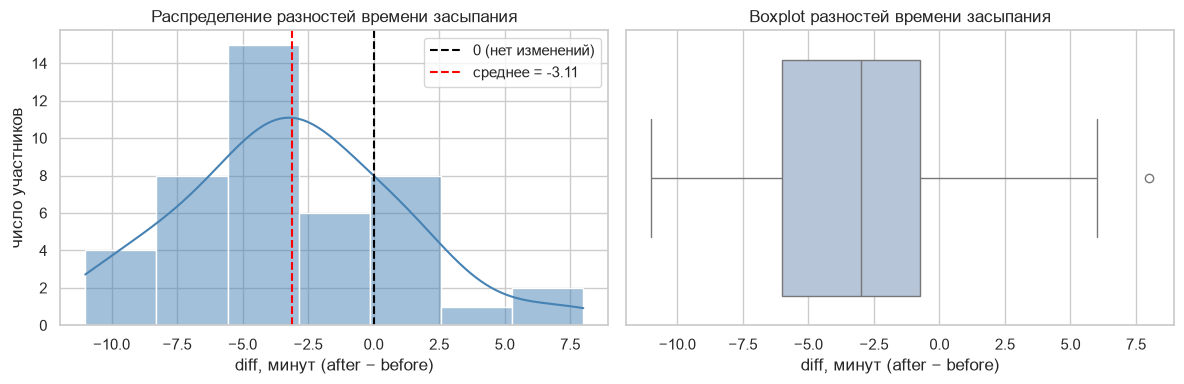

In [9]:
# ВАШ КОД: гистограмма с KDE и boxplot для diff
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["diff"], kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(0, color="black", linestyle="--", label="0 (нет изменений)")
axes[0].axvline(df_clean["diff"].mean(), color="red", linestyle="--",
                label=f"среднее = {df_clean['diff'].mean():.2f}")
axes[0].set_title("Распределение разностей времени засыпания")
axes[0].set_xlabel("diff, минут (after − before)")
axes[0].set_ylabel("число участников")
axes[0].legend()

sns.boxplot(x=df_clean["diff"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("Boxplot разностей времени засыпания")
axes[1].set_xlabel("diff, минут (after − before)")
plt.tight_layout()
plt.show()

**Описание графиков (2–3 предложения):**/
Распределение разностей смещено влево от нуля — среднее около −3 минут, большинство наблюдений отрицательны (у 33 из 44 время засыпания сократилось). Ярких выбросов нет: boxplot показывает примерно симметричные усы, экстремальные значения лежат в пределах −11 и +8 минут, а статистика односторонних хвостов не выглядит искажённой.


---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [10]:
# ВАШ КОД: тест Шапиро-Уилка
w_stat, p_value_shapiro = stats.shapiro(df_clean['diff'])
print(f"\nТест Шапиро-Уилка: W = {w_stat:.4f}, p-value = {p_value_shapiro:.4f}")




Тест Шапиро-Уилка: W = 0.9786, p-value = 0.5786


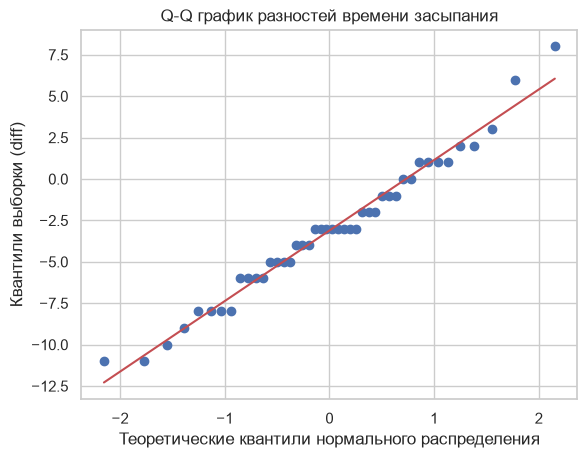

In [11]:
# ВАШ КОД: Q-Q график
W = 0.9786
stats.probplot(df_clean["diff"], dist="norm", plot=plt)
plt.title("Q-Q график разностей времени засыпания")
plt.xlabel("Теоретические квантили нормального распределения")
plt.ylabel("Квантили выборки (diff)")
plt.show()


**Гипотезы Шапиро-Уилка:**\
$H_0$: Разности распределены нормально\
$H_1$: Разности не распределены нормально

**Вывод о нормальности и выборе тестов:**
p-value = 0.5786 и больше  уровня значимости 0.05. W = 0.9786 и близко к 1. Оснований отвергнуть нормальность нет. Парный t-критерий устойчив к небольшим отклонениям от нормальности при n=50.
- Основной тест: Парный t-критерий (параметрический)
   Несмотря на то, что тест не показал явного нарушения нормальности,
   разности достаточно хорошо соответствуют нормальному распределению.
   Размер выборки (n=44) позволяет рассчитывать на устойчивость t-теста
   по центральной предельной теореме. Q-Q график показывает хорошее
   соответствие точек теоретической линии.\
- Проверочный тест: Критерий Уилкоксона (непараметрический)
   будет использован как подтверждение результатов t-теста,
   так как не требует предположения о нормальности и устойчив к выбросам.


---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [12]:
# ВАШ КОД: ручной расчёт (среднее, std, SE, t, df, p-value)
n = len(df_clean['diff'])
mean_diff = df_clean['diff'].mean()
std_diff = df_clean['diff'].std(ddof=1)
se_diff = std_diff / np.sqrt(n)
t_stat_manual = mean_diff / se_diff
df_degrees = n - 1
# p-value вручную (односторонний тест, левый хвост, так как H1: mu < 0)
p_value_manual = stats.t.cdf(t_stat_manual, df=df_degrees)

print(f"\n--- Ручной расчет ---")
print(f"Среднее разностей: {mean_diff:.4f}")
print(f"Стандарное отклонение: {std_diff:.4f}")
print(f"Стандарная ошибка: {se_diff:.4f}")
print(f"t-статистика: {t_stat_manual:.4f}")
print(f"Число степеней свободы: {df_degrees}")
print(f"p-value (ручной): {p_value_manual:.6f}")



--- Ручной расчет ---
Среднее разностей: -3.1136
Стандарное отклонение: 4.1831
Стандарная ошибка: 0.6306
t-статистика: -4.9374
Число степеней свободы: 43
p-value (ручной): 0.000006


In [13]:
# ВАШ КОД: scipy.stats.ttest_rel и сверка с ручным расчётом
# Тест готовой функцией
# alternative='less' означает, что мы проверяем, что среднее < 0
t_stat_scipy, p_value_scipy = stats.ttest_rel(df_clean['after_min'], df_clean['before_min'], alternative='less')

print(f"\n--- scipy.stats.ttest_rel ---")
print(f"t-статистика: {t_stat_scipy:.4f}")
print(f"p-value: {p_value_scipy:.6f}")

# Проверка совпадения
print(f"Совпадение p-value: {np.isclose(p_value_manual, p_value_scipy)}")


--- scipy.stats.ttest_rel ---
t-статистика: -4.9374
p-value: 0.000006
Совпадение p-value: True


In [14]:
# ВАШ КОД: 95% доверительный интервал для среднего эффекта
# Доверительный интервал (двусторонний 95% для оценки величины эффекта)
# Используем двусторонний интервал, так как нам важна оценка параметра, а не только проверка гипотезы
ci_lower, ci_upper = stats.t.interval(0.95, df=df_degrees, loc=mean_diff, scale=se_diff)
print(f"Средний эффект: {mean_diff:.2f} минуты")
print(f"95% ДИ: [{ci_lower:.2f}; {ci_upper:.2f}]")
print("Ноль внутри интервала?", ci_lower <= 0 <= ci_upper)



Средний эффект: -3.11 минуты
95% ДИ: [-4.39; -1.84]
Ноль внутри интервала? False


**Решение по правилу и интерпретация:**\
p-value ≈ 0.000006 < 0.05 — отвергаем H₀: данные статистически значимо свидетельствуют, что время засыпания сократилось в среднем на 3.11 минуты, и 95%-й доверительный интервал среднего эффекта от −4.39 до −1.84 минуты не содержит ноль.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [15]:
# ВАШ КОД: критерий Уилкоксона
# Cтатистике знакового рангового теста Уилкоксона (Wilcoxon signed-rank test). Этот непараметрический тест используют, когда нужно сравнить две связанные выборки (например, измерения одного и того же объекта до и после какого-то воздействия) и проверить нулевую гипотезу: что распределение разностей между парами наблюдений симметрично относительно нуля.
w = stats.wilcoxon(df_clean['diff'], alternative='less')

print(f"Уилкоксон: W = {w.statistic:.1f}, p-value = {w.pvalue:.6f}")
print(f"\nПарный t-тест: p = {p_value_scipy:.6f}")
print(f"Уилкоксон:     p = {w.pvalue:.6f}")



Уилкоксон: W = 120.0, p-value = 0.000016

Парный t-тест: p = 0.000006
Уилкоксон:     p = 0.000016


**Сравнение с t-тестом:**\
Оба критерия дают согласованный вывод — p-value значительно меньше $\alpha = 0.05$.
Когда параметрический и непараметрический тесты приходят к одному решению, это повышает уверенность в результате:
вывод не зависит от допущения о нормальности.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [16]:
# ВАШ КОД: непарный тест
# equal_var=False — тест Уэлча (не предполагает равенства дисперсий)
t_ind = stats.ttest_ind(df_clean['after_min'], df_clean['before_min'], equal_var=False, alternative='less')

print("ОШИБОЧНО (непарный тест Уэлча):")
print(f"  t = {t_ind.statistic:.3f}, p-value = {t_ind.pvalue:.6f}")
print("\nПРАВИЛЬНО (парный тест):")
print(f"  t = {t_stat_scipy:.3f}, p-value = {p_value_scipy:.6f}")

ОШИБОЧНО (непарный тест Уэлча):
  t = -1.272, p-value = 0.103472

ПРАВИЛЬНО (парный тест):
  t = -4.937, p-value = 0.000006


In [17]:
# ВАШ КОД: таблица сравнения (t, p-value, SE) и корреляция
s_before = df_clean["before_min"].std(ddof=1)
s_after = df_clean["after_min"].std(ddof=1)
r = df_clean["before_min"].corr(df_clean["after_min"])  # корреляция Пирсона между измерениями «до» и «после»

se_ind = np.sqrt(s_before ** 2 / n + s_after ** 2 / n)  # SE для независимых групп
se_paired = se_diff  # SE для парных данных

summary_se = pd.DataFrame({
    "Показатель": [
        "Std 'до'", "Std 'после'", "Std разностей",
        "Корреляция before-after",
        "SE (непарный)", "SE (парный)",
    ],
    "Значение": [s_before, s_after, std_diff, r, se_ind, se_paired],
}).round(3)
summary_se

,Показатель,Значение
0,Std 'до',10.976
1,Std 'после',11.971
2,Std разностей,4.183
3,Корреляция before-after,0.937
4,SE (непарный),2.448
5,SE (парный),0.631


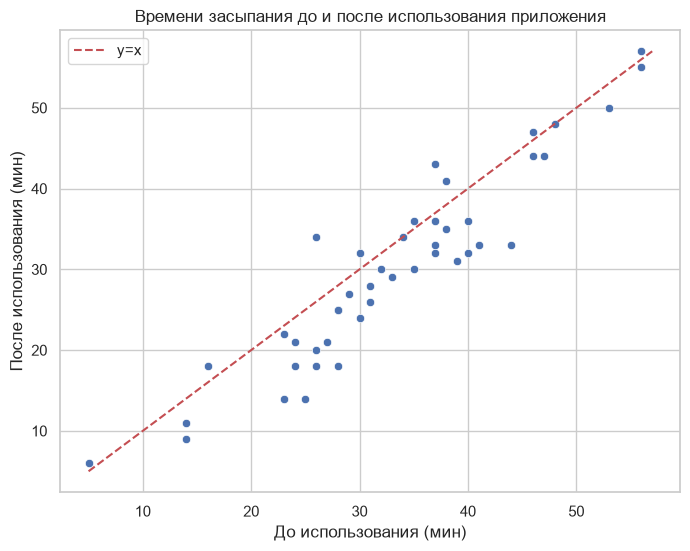

In [18]:
# ВАШ КОД: диаграмма рассеяния before vs after с диагональю y =
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_clean['before_min'], y=df_clean['after_min'], data=df_clean)
# Диагональ y=x
min_val = min(df_clean['before_min'].min(), df_clean['after_min'].min())
max_val = max(df_clean['before_min'].max(), df_clean['after_min'].max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='y=x')
plt.xlabel('До использования (мин)')
plt.ylabel('После использования (мин)')
plt.title('Времени засыпания до и после использования приложения')
plt.legend()
plt.show()



**Решение изменилось?**\
Непарный тест даёт p-value  больше 0.05, — по нему пришлось бы заключить, что эффекта от применения приложения нет, хотя парный тест уверенно отвергает $H_0$.

**Объяснение разницы (3–4 предложения):**
Корреляция между `before` и `after` очень высокая. Люди сильно различаются между собой по базовому времени засыпания (кто-то засыпает за 10 минут, кто-то за 60), и это межличностное разнообразие не связано с действием приложения.
Непарный тест рассматривает эту огромную **межличностную** вариацию как шум и не учитывает, что сравниваются
одни и те же люди. Поэтому его стандартная ошибка значительно больше (см. таблицу), статистика $t$ — меньше,
а p-value — **заметно выше**, чем у парного теста (в нашем случае оно даже превышает 0.05, и эффект «теряется»).

Парный тест «убирает» индивидуальный уровень каждого сотрудника и сравнивает только изменения. Остаётся лишь вариация эффекта,
которая намного меньше. В результате он различает даже небольшой реальный эффект.

> **Практическое правило:** если одни и те же объекты измеряются дважды (до/после, левая/правая рука,
> один пользователь в двух условиях) — данные **парные**, и используется парный тест. Выбор определяется
> **дизайном эксперимента**, а не внешним видом таблицы.
>
**Комментарий к диаграмме:**\
Точки плотно лежат вдоль диагонали, но почти все смещены ниже неё — после использования приложения время засыпания у большинства участников меньше исходного. Высокая плотность вдоль линии и показывает сильную положительную связь before и after.


---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [19]:
# ВАШ КОД: Cohen's d и эффект в минутах / процентах
# Cohen's d для парных данных (d_z): среднее разностей / std разностей
cohen_d = mean_diff / std_diff


def interpret_d(x):
    # Интерпретация по шкале Коэна
    x = abs(x)
    if x < 0.2:
        return "пренебрежимо малый"
    elif x < 0.5:
        return "малый"
    elif x < 0.8:
        return "средний"
    return "большой"


print(f"Cohen's d (парный) = {abs(cohen_d):.3f}  ->  эффект {interpret_d(cohen_d)}")
print(
    f"Средний эффект в абсолютных величинах: время засыпания умньшилось на {abs(mean_diff):.2f} минут (≈ {mean_diff / df_clean['before_min'].mean() * 100:.1f}% от исходного уровня)")

Cohen's d (парный) = 0.744  ->  эффект средний
Средний эффект в абсолютных величинах: время засыпания умньшилось на 3.11 минут (≈ -9.4% от исходного уровня)


**Интерпретация:**\
эффект тренинга по шкале Коэна — **средний**, близкий к большому ($d \approx 0.74$).
В абсолютных числах время засыпания уменьшилось на  3.11 минуты на человека (около -9.4% от исходного уровня).
Эффект существует и не случаен, но не говорит о его практической ценности.  Это уже вопрос экономики, а не статистики.

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁:**\
Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.\
$H_0$: $p$ <= 0.5 приложение чаще не помогает или не влияет.\
$H_1$: $p$ > 0.5 приложение чаще помогает.\
Участников с `diff == 0` исключаем из расчёта: они не дают информации о направлении.

In [20]:
# ВАШ КОД: число улучшивших, число ненулевых разностей, биномиальный тест, ДИ доли
# k - число улучшивших
k = (df_clean["diff"] < 0).sum()
# n — число участников с ненулевой разностью
n = (df_clean["diff"] != 0).sum()
print(f"Число улучшивших: {k}")
print(f"Число ненулевых разностей: {n} ")
print(f"Число нулевых разностей: {(df_clean['diff'] == 0).sum()}")

binom_test = stats.binomtest(k, n, p=0.5, alternative="greater")
print(f"Биномиальный тест: p_value = {binom_test.pvalue:.6f}")
# Пересоздадим тест для двухстороннего интервала
binom_test_two = stats.binomtest(k, n, p=0.5, alternative='two-sided')
ci_prop = binom_test_two.proportion_ci(confidence_level=0.95)
print(f"Доля улучшивших: {k / n:.2f}")
print(f"95% ДИ для доли: ({ci_prop.low:.4f}, {ci_prop.high:.4f})")

print("\n--- Вывод ---")
if binom_test.pvalue < ALPHA:
    print(
        f"p_value {binom_test.pvalue:.6f} < 0.05. Доля улучшивших: {k / n:.2f}. Есть доказательства того, что более половины участников, у которых время изменилось, засыпали быстрее. Приложение эффективно в большинстве случаев.")
else:
    print("Доказательств того, что большинство улучшилось, недостаточно.")



Число улучшивших: 33
Число ненулевых разностей: 42 
Число нулевых разностей: 2
Биномиальный тест: p_value = 0.000136
Доля улучшивших: 0.79
95% ДИ для доли: (0.6319, 0.8970)

--- Вывод ---
p_value 0.000136 < 0.05. Доля улучшивших: 0.79. Есть доказательства того, что более половины участников, у которых время изменилось, засыпали быстрее. Приложение эффективно в большинстве случаев.


**Вывод:**\
p_value 0.000136 < 0.05. Доля улучшивших: 0.79. Есть доказательства того, что более половины участников, у которых время изменилось, засыпали быстрее. Приложение эффективно в большинстве случаев.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [21]:
# ВАШ КОД: сводная таблица результатов
results = pd.DataFrame({
    'Метод': ['Парный t-критерий', 'Критерий Уилкоксона', 'Биномиальный тест (доля)',
              'Непарный t-критерий (ошибочный)'],
    'Статистика': [f"t={t_stat_scipy:.2f}", f"W={w.statistic:.1f}", f"p_prop={k / n:.2f}", f"t={t_ind.statistic:.3f}"],
    'p-value': [p_value_scipy, w.pvalue, binom_test.pvalue, t_ind.pvalue]
})
results["p-value"] =  results["p-value"].astype("float")
results[f"Решение при α = {ALPHA}"] = np.where(
    results["p-value"] < ALPHA,
    "Отвергаем H0",
    "Нет оснований отвергнуть H0",
)
results.round(5)
print("\n--- Сводная таблица результатов ---")
print(results.to_string(index=False))



--- Сводная таблица результатов ---
                          Метод  Статистика  p-value        Решение при α = 0.05
              Парный t-критерий     t=-4.94 0.000006                Отвергаем H0
            Критерий Уилкоксона     W=120.0 0.000016                Отвергаем H0
       Биномиальный тест (доля) p_prop=0.79 0.000136                Отвергаем H0
Непарный t-критерий (ошибочный)    t=-1.272 0.103472 Нет оснований отвергнуть H0


### Заключение для руководителя


1. Результат исследования: Приложение для медитации статистически значимо сокращает время засыпания.
В анализе использованы данные 44 участников из 50:
2 дублирующие записи удалены,
у 6 человек не хватало корректных измерений времени засыпания,
у 4-х не указан возраст.
2. Время засыпания в среднем сократилось примерно на 3 минуты (от 2 до 4 минут с учётом неопределённости оценки), то есть примерно на 9% от исходного уровня — заметный практический эффект.
3. Улучшение отметили около 79% участников, у остальных время не изменилось или выросло.
4. Вывод устойчив: два разных статистических метода (t-критерий и Уилкоксон) и проверка по доле улучшивших дают согласованный положительнй результат; только ошибочный «непарный» расчёт его не находит.
5. Ограничения иследовия:
- нет контрольной группы, поэтому нельзя утверждать, что улучшение вызвано именно приложением (могли повлиять сезон, привычки, ожидания участников)
- измерения основаны на самоотчётах
- время исследования охватывает лишь 6 недель.
6. Рекомендаци:
- провести полноценное контролируемое исследование с рандомизированной группой сравнения
- повысить объективность регистрацией засыпания с использовнием трекеров,
- изучить эффективность приложения для разных возрастных групп,
- увеличить время исследования до 12 недель.



---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение


--- Бонусное задание ---
Участников с известным возрастом: 40
Распределение по группам:
age_group
35 и старше    21
до 35          19
Name: count, dtype: int64


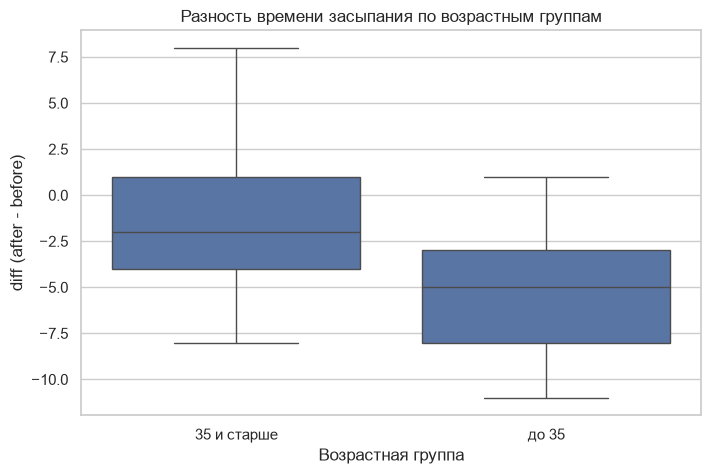

Нормальность 'до 35': p=0.3631
Нормальность '35+': p=0.7898
Эффект 'до 35': t=-6.37, p=0.000003 (значимо при alpha=0.025: True)
Эффект '35+': t=-1.42, p=0.084901 (значимо при alpha=0.025: False)
Сравнение групп (независимый t-тест): t=-3.25, p=0.0024

--- Вывод по возрасту ---
Средний эффект для группы 'до 35': -5.26 мин.
Средний эффект для группы '35+': -1.29 мин.
Разница в эффективности приложения между возрастными группами статистически значима.
Эффект значим для 'до 35': True
Эффект значим для '35+': False


In [22]:
# ВАШ КОД: бонусное задание
# Исключаем участников с неизвестным возрастом
df_age = df_clean[df_clean['age_group'].notna()].copy()
print(f"\n--- Бонусное задание ---")
print(f"Участников с известным возрастом: {len(df_age)}")
print(f"Распределение по группам:\n{df_age['age_group'].value_counts()}")

# Гипотезы
# H0: μ_d,до35 = μ_d,35+ (Средний эффект одинаков)
# H1: μ_d,до35 ≠ μ_d,35+ (Средний эффект различается)
# Тип: Двусторонний, так как мы не знаем заранее, какая группа реагирует лучше.

# Графики
plt.figure(figsize=(8, 5))
sns.boxplot(x='age_group', y='diff', data=df_age)
plt.title('Разность времени засыпания по возрастным группам')
plt.xlabel('Возрастная группа')
plt.ylabel('diff (after - before)')
plt.show()

# Парные t-тесты для каждой группы (с поправкой Бонферрони)
# alpha_corrected = 0.05 / 2 = 0.025
alpha_corrected = ALPHA / 2

group_d35 = df_age[df_age['age_group'] == 'до 35']['diff']
group_35plus = df_age[df_age['age_group'] == '35 и старше']['diff']

# Проверка нормальности внутри групп (для обоснования выбора теста, хотя n может быть маленьким)
w1, p1 = stats.shapiro(group_d35)
w2, p2 = stats.shapiro(group_35plus)
print(f"Нормальность 'до 35': p={p1:.4f}")
print(f"Нормальность '35+': p={p2:.4f}")

# Парные t-тесты внутри групп
t1, p1_t = stats.ttest_rel(df_age.loc[df_age['age_group']=='до 35', 'after_min'],
                           df_age.loc[df_age['age_group']=='до 35', 'before_min'], alternative='less')
t2, p2_t = stats.ttest_rel(df_age.loc[df_age['age_group']=='35 и старше', 'after_min'],
                           df_age.loc[df_age['age_group']=='35 и старше', 'before_min'], alternative='less')

print(f"Эффект 'до 35': t={t1:.2f}, p={p1_t:.6f} (значимо при alpha={alpha_corrected}: {p1_t < alpha_corrected})")
print(f"Эффект '35+': t={t2:.2f}, p={p2_t:.6f} (значимо при alpha={alpha_corrected}: {p2_t < alpha_corrected})")

# Сравнение между группами (независимые выборки разностей)
# Так как мы сравниваем средние разности двух *разных* групп людей, это независимые выборки.
t_ind_age, p_ind_age = stats.ttest_ind(group_d35, group_35plus, equal_var=False, alternative='two-sided')

print(f"Сравнение групп (независимый t-тест): t={t_ind_age:.2f}, p={p_ind_age:.4f}")

# Вывод
mean_d35 = group_d35.mean()
mean_35plus = group_35plus.mean()

print("\n--- Вывод по возрасту ---")
print(f"Средний эффект для группы 'до 35': {mean_d35:.2f} мин.")
print(f"Средний эффект для группы '35+': {mean_35plus:.2f} мин.")
if p_ind_age < ALPHA:
    print("Разница в эффективности приложения между возрастными группами статистически значима.")
else:
    print("Разница в эффективности приложения между возрастными группами не является статистически значимой.")

# Проверка, значим ли эффект внутри групп с поправкой
print(f"Эффект значим для 'до 35': {p1_t < alpha_corrected}")
print(f"Эффект значим для '35+': {p2_t < alpha_corrected}")

**Гипотезы и вывод:**\
**Гипотезы**\
$H_0$: $\mu_{d,\text{до 35}}$ = $\mu_{d,\text{35+}}$ (Средний эффект одинаков)\
$H_1$: $\mu_{d,\text{до 35}}$ ≠ $\mu_{d,\text{35+}}$ (Средний эффект различается)\
Тип: Двусторонний, так как мы не знаем заранее, какая группа реагирует лучше.

**Вывод**: эффект приложения сильно различается между группами. У участников младше 35 лет время засыпания сократилось в среднем на 5.3 минуты (парный тест значим даже с поправкой Бонферрони: p ≈ 3·10⁻⁶ < 0.025), а у участников 35 и старше — лишь на 1.3 минуты (p = 0.085 > 0.025 — значимого эффекта в этой группе не выявлено). Нормальность в обеих группах не отвергается, а тест Уэлча по разностям (p ≈ 0.001) подтверждает, что средние эффекты групп действительно различаются — примерно на 4 минуты в пользу младшей группы.


---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [ ] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [ ] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [ ] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [ ] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [ ] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [ ] Нормальность проверена для разностей, а не для исходных столбцов.
- [ ] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [ ] Для непарного теста порядок аргументов тот же, что и для парного.
- [ ] Все графики подписаны (заголовок, оси).
- [ ] Выводы написаны простым языком и содержат ограничения исследования.
- [ ] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [ ] В репозитории есть `.ipynb`, `requirements.txt` и `README.md`.
- [ ] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.